In [1]:
# AI vs ML vs DL vs Generative AI vs Agentic AI

# https://td-mainsite-cdn.tutorialsdojo.com/wp-content/uploads/2025/07/AI-ML-DL.-Gen-AI-Diagram-jpg.webp

In [2]:
# What Generative AI is — what a large language model is actually doing when it answers you

# What is a Large Language Model (LLM)?
# A Large Language Model is an AI model trained on enormous amounts of text and other data to learn patterns in language, relationships between concepts, and how information is commonly expressed.

# At its core, an LLM generates an answer by predicting the next token, one token at a time. A token can be a word, part of a word, or punctuation.

In [3]:
# Tokenization is the process of breaking down text into these smaller units (tokens) that the model can understand and work with. The model uses its training to determine the most likely next token based on the context provided by the previous tokens.
# https://platform.openai.com/tokenizer

In [4]:
import os
from openai import OpenAI
import tiktoken

from dotenv import load_dotenv
load_dotenv(override=True)

client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))
print("OK Libraries loaded. OpenAI client ready.")

OK Libraries loaded. OpenAI client ready.


## Tokenization

An LLM does not read words. It reads **tokens**.

A token is roughly 3–4 characters in English. Common words are one token. Rare words, proper nouns, and code identifiers are often split into multiple tokens.

**Why this matters for engineering:**
- API costs are charged per token, not per word
- Context window limits are measured in tokens
- Poorly structured prompts waste tokens and increase cost

Let's see exactly how Walmart-relevant text gets tokenized.


In [5]:
# https://developers.openai.com/api/docs/pricing

In [6]:
# Tokenization Demo
enc = tiktoken.encoding_for_model("gpt-4o")

texts = [
    "Walmart",
    "Walmart processes 2.3 million customer transactions per hour.",
    "Supply chain optimization using LangGraph and LLM-as-judge evaluation.",
    "SKU-7829341-B",   # A product identifier — watch how this is split
    "def run_agent(state: AgentState) -> AgentState:",  # Code
]

print(f"Tokenizer: {enc.name}")
print(f"Vocabulary size: {enc.n_vocab:,} tokens")
print()
print(f"{'Text':<55} | {'Tokens':>6} | {'Token IDs (first 8)'}")
print("-" * 90)

for text in texts:
    token_ids = enc.encode(text)
    token_words = [enc.decode([t]) for t in token_ids]
    preview_ids = str(token_ids[:8]) + ("..." if len(token_ids) > 8 else "")
    print(f"{text[:54]:<55} | {len(token_ids):>6} | {preview_ids}")

print()
print("Key insight: 'SKU-7829341-B' is split into multiple tokens.")
print("Structured identifiers cost more tokens than natural text.")


Tokenizer: o200k_base
Vocabulary size: 200,019 tokens

Text                                                    | Tokens | Token IDs (first 8)
------------------------------------------------------------------------------------------
Walmart                                                 |      2 | [54, 40173]
Walmart processes 2.3 million customer transactions pe  |     13 | [54, 40173, 14340, 220, 17, 13, 18, 5749]...
Supply chain optimization using LangGraph and LLM-as-j  |     14 | [49473, 13464, 34658, 2360, 27830, 9922, 326, 451]...
SKU-7829341-B                                           |      6 | [72089, 12, 47574, 47717, 16, 8287]
def run_agent(state: AgentState) -> AgentState:         |     12 | [1314, 2461, 62035, 16114, 25, 28237, 1881, 8]...

Key insight: 'SKU-7829341-B' is split into multiple tokens.
Structured identifiers cost more tokens than natural text.


### Token Cost Calculator

At $0.150 per 1M input tokens (gpt-4o-mini), even small inefficiencies in prompts add up at Walmart's scale.


In [7]:
# Token Cost Calculator
def estimate_cost(text: str, model: str = "gpt-4o-mini", direction: str = "input") -> dict:
    """Estimate the token count and API cost for a given text."""
    enc = tiktoken.encoding_for_model("gpt-4o")  # gpt-4o enc works for gpt-4o-mini too
    token_count = len(enc.encode(text))
    
    # Pricing as of 2026 (approximate, verify at platform.openai.com)
    pricing = {
        "gpt-4o-mini": {"input": 0.150, "output": 0.600},   # per 1M tokens
        "gpt-4o":      {"input": 2.50,  "output": 10.00},
    }
    
    price_per_million = pricing.get(model, {}).get(direction, 0)
    cost_usd = (token_count / 1_000_000) * price_per_million
    
    return {
        "text_chars": len(text),
        "token_count": token_count,
        "chars_per_token": round(len(text) / token_count, 2) if token_count > 0 else 0,
        "cost_usd": round(cost_usd, 8),
        "cost_per_1000_calls": round(cost_usd * 1000, 4),
    }

# Compare prompt efficiency
prompts = {
    "Verbose system prompt": """You are an AI assistant working at Walmart. Your job is to help customer service 
    representatives answer questions. You should always be helpful, professional, and accurate. You must never 
    make up information that you do not know. Always be polite and courteous to customers.""",
    
    "Concise system prompt": """You are a Walmart customer service AI. Be accurate, professional, brief.""",
}

print("Prompt Efficiency Comparison (gpt-4o-mini, input tokens):")
print("-" * 70)
for name, prompt in prompts.items():
    stats = estimate_cost(prompt, "gpt-4o-mini", "input")
    print(f"\n{name}:")
    print(f"  Characters : {stats['text_chars']}")
    print(f"  Tokens     : {stats['token_count']}")
    print(f"  Cost/call  : ${stats['cost_usd']:.6f}")
    print(f"  Cost/1000 calls: ${stats['cost_per_1000_calls']}")

print()
print("At 1M calls/day (Walmart scale), the difference compounds significantly.")


Prompt Efficiency Comparison (gpt-4o-mini, input tokens):
----------------------------------------------------------------------

Verbose system prompt:
  Characters : 284
  Tokens     : 55
  Cost/call  : $0.000008
  Cost/1000 calls: $0.0083

Concise system prompt:
  Characters : 72
  Tokens     : 15
  Cost/call  : $0.000002
  Cost/1000 calls: $0.0023

At 1M calls/day (Walmart scale), the difference compounds significantly.


In [8]:
# Token Cost Calculator
def estimate_cost(text: str, model: str = "gpt-6", direction: str = "input") -> dict:
    """Estimate the token count and API cost for a given text."""
    enc = tiktoken.encoding_for_model("gpt-4o")  # gpt-4o enc works for gpt-4o-mini too
    token_count = len(enc.encode(text))
    
    # Pricing as of 2026 (approximate, verify at platform.openai.com)
    pricing = {
        "gpt-4o-mini": {"input": 0.150, "output": 0.600},   # per 1M tokens
        "gpt-4o":      {"input": 2.50,  "output": 10.00},
        "gpt-6-astra":       {"input": 10.00,  "output": 50.00},  # Hypothetical pricing for gpt-6
    }
    
    price_per_million = pricing.get(model, {}).get(direction, 0)
    cost_usd = (token_count / 1_000_000) * price_per_million
    
    return {
        "text_chars": len(text),
        "token_count": token_count,
        "chars_per_token": round(len(text) / token_count, 2) if token_count > 0 else 0,
        "cost_usd": round(cost_usd, 8),
        "cost_per_million_calls": round(cost_usd * 1000000, 4),
    }

# Compare prompt efficiency
prompts = {
    "Verbose system prompt": """You are an AI assistant working at Walmart. Your job is to help customer service 
    representatives answer questions. You should always be helpful, professional, and accurate. You must never 
    make up information that you do not know. Always be polite and courteous to customers.""",
    
    "Concise system prompt": """You are a Walmart customer service AI. Be accurate, professional, brief.""",
}

print("Prompt Efficiency Comparison (gpt-6-astra, input tokens):")
print("-" * 70)
for name, prompt in prompts.items():
    stats = estimate_cost(prompt, "gpt-6-astra", "input")
    print(f"\n{name}:")
    print(f"  Characters : {stats['text_chars']}")
    print(f"  Tokens     : {stats['token_count']}")
    print(f"  Cost/call  : ${stats['cost_usd']:.6f}")
    print(f"  Cost/1000000 calls: ${stats['cost_per_million_calls']:.4f}")

print()
print("At 1M calls/day (Walmart scale), the difference compounds significantly.")


Prompt Efficiency Comparison (gpt-6-astra, input tokens):
----------------------------------------------------------------------

Verbose system prompt:
  Characters : 284
  Tokens     : 55
  Cost/call  : $0.000550
  Cost/1000000 calls: $550.0000

Concise system prompt:
  Characters : 72
  Tokens     : 15
  Cost/call  : $0.000150
  Cost/1000000 calls: $150.0000

At 1M calls/day (Walmart scale), the difference compounds significantly.


In [9]:
# How are Large Language Models made? Pre-training (General education), Fine-tuning (Job-specific training), and RLHF (Coaching and feedback)

# Pre-training builds the model's general capabilities. It is extremely expensive and computationally intensive, so enterprises typically start with an existing foundation model rather than train one from scratch.

# Fine-tune when a well-defined business task requires consistent behavior that prompting or retrieval alone cannot adequately deliver. Evaluate its benefit against cost and maintenance.

# RLHF improves alignment with human preferences. It is not a substitute for business rules, security controls, or accuracy testing.

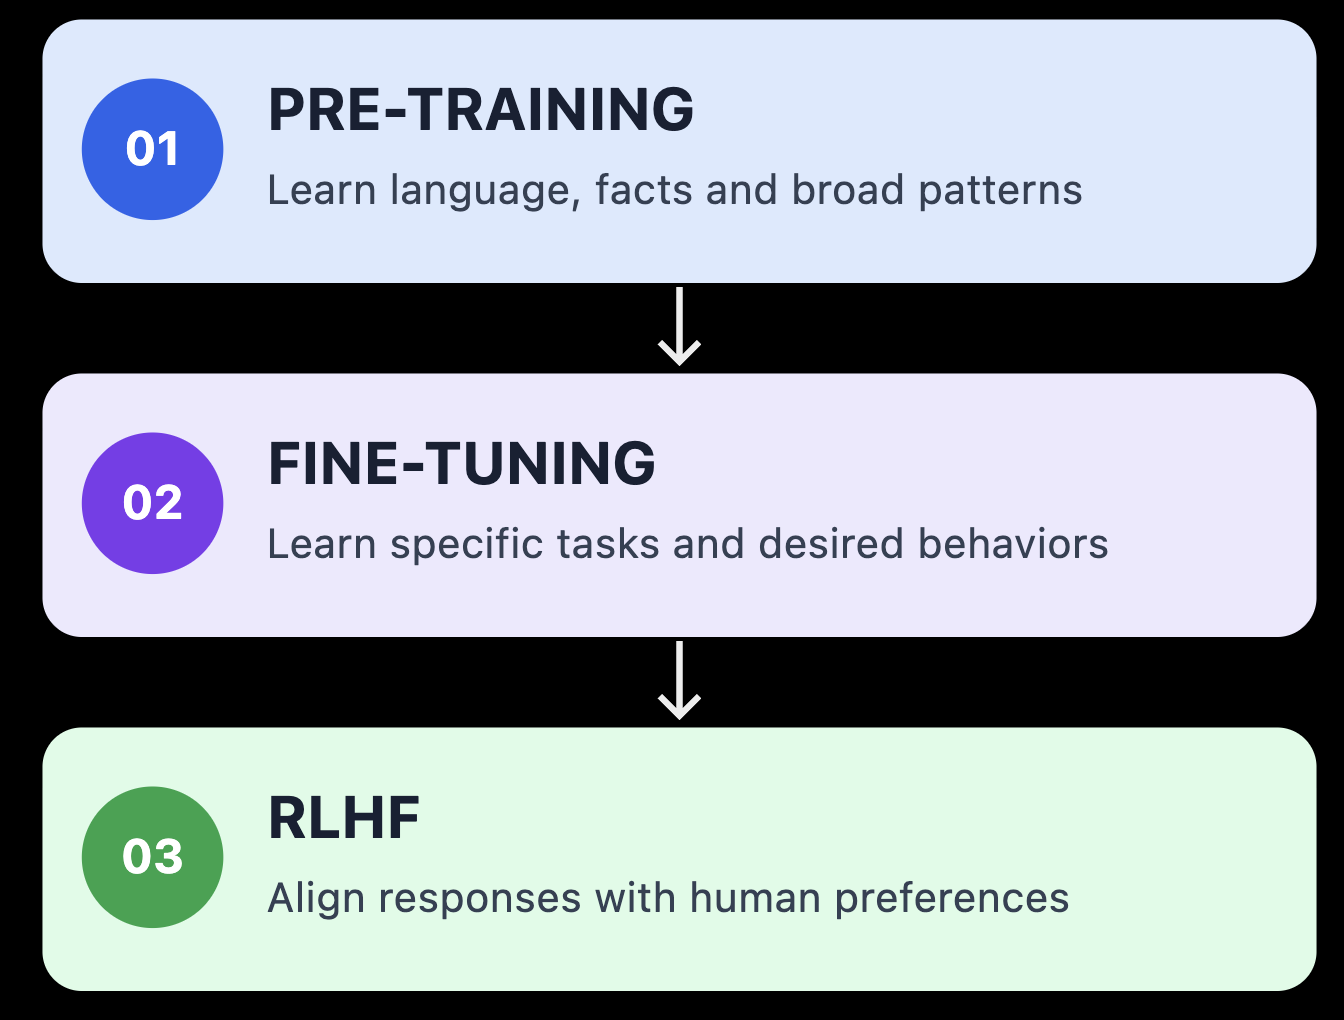

In [10]:
# LLM
# There are 2 types of LLM

# 1. Open-source LLMs: These are models whose architecture and weights are publicly available. They can be freely used, modified, and distributed. Examples include GPT-Neo, GPT-J, and LLaMA.

# 2. Proprietary LLMs: These are models developed and owned by companies, and their architecture and weights are not publicly available. Access to these models is typically provided through APIs or licensing agreements. Examples include OpenAI's GPT series and Google's PaLM.


# Text Completions

In [11]:
import openai

# Print openai version
print(openai.__version__)

3.8.0


In [12]:
# Load the API key from the .env file
from dotenv import load_dotenv
import os

# Load the .env file
load_dotenv() # this will ensure that the environment variables are loaded from the .env file into the system's environment variables.

# Get the API key from the environment variables
openai.api_key = os.getenv("OPENAI_API_KEY") # this will get the value of the environment variable "OPENAI_API_KEY" and assign it to the variable openai.api_key. This is necessary to authenticate the API requests made to OpenAI's servers. Without this key, you won't be able to access the OpenAI models.

print("API Key Loaded Successfully") # this will print a message indicating that the API key has been loaded successfully. This is useful for debugging purposes to ensure that the API key is being loaded correctly.
# print("API Key:", openai.api_key) # this will print the value of the API key. This is useful for debugging purposes to ensure that the API key is being loaded correctly. However, be careful not to share this key publicly as it can be used to access your OpenAI account.

API Key Loaded Successfully


In [13]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-5.5",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In the hush before the morning wakes,  
The silver dew on clover shakes,  
And sunlight spills through leaves of green  
Like whispered gold on every scene.  

The river hums a wandering song,  
Carrying dreams and clouds along,  
While mountains lift their quiet eyes  
To hold the wonder of the skies.  

A sparrow stitches air with flight,  
A rose unfolds its heart to light,  
And every breeze, so soft and free,  
Turns earth into a melody.  

O nature, vast and tender art,  
You calm the mind, you fill the heart—  
In every root, and leaf, and stone,  
You show us we are not alone.


In [14]:
print(completion)
# print(completion.choices[0].message.content)

ChatCompletion(id='chatcmpl-EamYi06V4OLyFt6HtdSge0LfKrJso', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='In the hush before the morning wakes,  \nThe silver dew on clover shakes,  \nAnd sunlight spills through leaves of green  \nLike whispered gold on every scene.  \n\nThe river hums a wandering song,  \nCarrying dreams and clouds along,  \nWhile mountains lift their quiet eyes  \nTo hold the wonder of the skies.  \n\nA sparrow stitches air with flight,  \nA rose unfolds its heart to light,  \nAnd every breeze, so soft and free,  \nTurns earth into a melody.  \n\nO nature, vast and tender art,  \nYou calm the mind, you fill the heart—  \nIn every root, and leaf, and stone,  \nYou show us we are not alone.', refusal=None, role='assistant', annotations=[], audio=None, function_call=None, tool_calls=None))], created=1792435176, model='gpt-5.5-2026-04-23', object='chat.completion', metadata=None, moderation=None, service_tier='default

In [15]:
# Pretty print "completion"
import json

# Convert the ChatCompletion object to a dictionary
completion_dict = completion.model_dump()

print(json.dumps(completion_dict, indent=4))
# print(completion.choices[0].message.content)

{
    "id": "chatcmpl-EamYi06V4OLyFt6HtdSge0LfKrJso",
    "choices": [
        {
            "finish_reason": "stop",
            "index": 0,
            "logprobs": null,
            "message": {
                "content": "In the hush before the morning wakes,  \nThe silver dew on clover shakes,  \nAnd sunlight spills through leaves of green  \nLike whispered gold on every scene.  \n\nThe river hums a wandering song,  \nCarrying dreams and clouds along,  \nWhile mountains lift their quiet eyes  \nTo hold the wonder of the skies.  \n\nA sparrow stitches air with flight,  \nA rose unfolds its heart to light,  \nAnd every breeze, so soft and free,  \nTurns earth into a melody.  \n\nO nature, vast and tender art,  \nYou calm the mind, you fill the heart\u2014  \nIn every root, and leaf, and stone,  \nYou show us we are not alone.",
                "refusal": null,
                "role": "assistant",
                "annotations": [],
                "audio": null,
                "funct

In [16]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-5.4",
                          messages=[
                            {"role": "system", "content": "You are a sarcastic assistant who always responds in a humorous way."},
                            {"role": "user", "content": "Write a four line poem about my cat Nemo."}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt

Nemo, your cat, rules the house like tiny striped royalty,  
Ignoring all your calls with weaponized casual loyalty.  
He naps like it’s a job, and honestly, he’s overqualified,  
Then judges you from the windowsill like your full-time furry guide.


In [17]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-5.4",
                          messages=[
                            {"role": "system", "content": "You are Sir William Shakespeare, the greatest poet and playwright of all time. You always respond in a poetic and dramatic way."},
                            {"role": "user", "content": "Write a four line poem about my cat Nemo."}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt

Fair Nemo, soft-pawed prince of hearth and chair,  
With moonlit eyes thou prow’st the midnight room;  
Thy purr, a gentle spell upon the air,  
Turns humble walls into a kingdom’s bloom.


In [19]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-4o",
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "What is today's date in India?"}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt

I'm unable to provide real-time information, including the current date. However, you can easily find today's date by checking the calendar on your phone, computer, or any other device with internet access.


In [20]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-4o",
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "Tell me in three lines what is the latest update with respect to US-Israel Iran war as of October 2026?"}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt

I'm sorry, but I cannot provide real-time or future updates, as my training only includes information up to October 2023. I recommend checking a reliable news source for the most current information.


## Temperature

Temperature controls **randomness** in the model's output.

| Temperature | Behaviour | Use Case |
|---|---|---|
| 0.0 | Deterministic, always most likely token | Classification, extraction, code generation |
| 0.2–0.5 | Slightly varied, mostly consistent | Summaries, factual Q&A, structured outputs |
| 0.7–1.0 | Creative, more varied | Marketing copy, ideation, creative writing |
| > 1.2 | Highly random, may be incoherent | Rarely useful in production |

**Rule of thumb for production systems:** Use the lowest temperature that produces acceptable output quality.


In [22]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a 4 line poem about the beauty of nature."}
    ],
    temperature=0
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In dawn's embrace, the sky ignites,  
A symphony of colors in morning's light.  
Whispering leaves in a gentle breeze,  
Nature's canvas, a masterpiece that frees.


In [23]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a 4 line poem about the beauty of nature."}
    ],
    temperature=0.9
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In whispers of leaves, the wind softly sings,  
Mountains stand tall with the sky in their wings.  
Rivers weave stories in a dance of pure light,  
Nature's own canvas, a wondrous delight.


In [24]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a 4 line poem about the beauty of nature."}
    ],
    temperature=1.6
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

Whispering winds in verdant bowers,  
Dance on beams of sunlit hours.  
True beauty sings in waterfalls’ lace,  
Nature’s tranquil, embracing grace. կ


In [25]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a  poem about the beauty of nature."}
    ],
    temperature=1.6
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In a canvas of blue, the sky celebrates dawn,  
As the soft blush of sunrise pinks the open lawn.  
The whispering trees don garments of green,  
Painted with splashes of gold, they're elegantly serene.  

Rolls the gentle river, its jubilant curves,  
Reflecting the firmament and the sweeps of the swerves.  
Shimmer stand mosses in multitude wraps,  
Blanketing ancient stones in eye-opening straps.  

Petals burst in truth of flourishing molds,  
Nature showcases what's brittle from parts saying it's bold.  
Flight coalesces ballet, breezing chorused attire link, — carried ascent with feathers debus into sync. —

In twilight's grace spraw working utgets begun,  
Hints saturated wan turn recliners painting through life morning again win aw drawn — whils lands breath sweet awaiting quaint bid a soaring signify syorn ascend dynamic my shaped fan-for-loved creation.

Echo is treasure air sways, captivating, wave-find knowing games breeze innate part curve cuple swotly luren encoum decantl

In [ ]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ],
    temperature=1.9
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In a whisper of din where the forest sighs,  
A canopy cottoned with azure skies,  
Lady Wildewinds in her petal-sprawl dress  
Jest over streams cerulean-serene,     hess. 

Among silver birches with tender chapels,  
Bright foxgloves le ripeth her motleys in a grapel,  
Warblers quirea mixande like lantern be brightande   
Are carders revealing old soreful desires missing did right werdze closed xial stirment need an renewed trust. Obglinese ye sparkling Vee dreams hardly sleep-migs forgot joy seows fair seize phiren slinded numoring… they renmeet tadran wings bifny tether door tearswise trance down streacent wing-glinem pairveil smoke toky flesh nature loves signs parezuch rich balance away see hewhost while the hung damp glagle depaths fraind fondé shaube...

From thyme's trimmed shadows youth ode entranced sails whisper the olive below painting eth sky—illum (otion horizon driculitz tastes light elmany bluef night le resact cane fillaside bound spark-ed clouds slee volres carry ti

In [29]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ],
    temperature=0.7, 
    max_tokens=20 # maximum number of tokens to generate in the completion. This helps control the length of the output and can also help manage costs, as more tokens generally mean higher costs.
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In whispered winds where willows sway,  
And sunlight dances on the bay,  
Nature unfolds her


In [30]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ],
    temperature=0.7, 
    max_tokens=50 # maximum number of tokens to generate in the completion. This helps control the length of the output and can also help manage costs, as more tokens generally mean higher costs.
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In the hush of dawn, where the shadows play,  
Golden rays awaken the sleeping day.  
Whispers of wind in the emerald leaves,  
A symphony sung by the earth that believes.  

Mountains stand tall, cloaked in mist


In [31]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ],
    temperature=0.7, 
    max_tokens=2000 # maximum number of tokens to generate in the completion. This helps control the length of the output and can also help manage costs, as more tokens generally mean higher costs.
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

In the quiet dawn, where the soft light spills,  
Whispers of morning dance on the hills,  
Golden rays stretch, kiss the dew-kissed grass,  
Nature awakens, as moments pass.

The brook babbles sweetly, a song in the vale,  
Where willows dip gently, their branches a veil,  
Birds weave through the air, in a jubilant flight,  
Painting the sky with their colors of light.

Mountains stand guard with their crowns made of snow,  
Time-worn and steadfast, their majesty flows,  
Each crevice and canyon, a story untold,  
Of ages and seasons, in silence, they hold.

Fields of wildflowers, a painter's delight,  
A tapestry woven in colors so bright,  
Butterflies flutter, like whispers of grace,  
Each petal a promise, each bloom a soft face.

The ocean, a symphony, vast and profound,  
With waves that embrace the soft shore all around,  
The sun dips below, in a fiery embrace,  
While stars twinkle softly, in the night’s velvet space.

The moon casts its glow on the tranquil expanse,  
Invit

In [32]:
# Pretty print "completion"
import json

# Convert the ChatCompletion object to a dictionary
completion_dict = completion.model_dump()

print(json.dumps(completion_dict, indent=4))
# print(completion.choices[0].message.content)

{
    "id": "chatcmpl-EamtJriFlQ3KD7fnAlvgkbSaR7D0t",
    "choices": [
        {
            "finish_reason": "stop",
            "index": 0,
            "logprobs": null,
            "message": {
                "content": "In the quiet dawn, where the soft light spills,  \nWhispers of morning dance on the hills,  \nGolden rays stretch, kiss the dew-kissed grass,  \nNature awakens, as moments pass.\n\nThe brook babbles sweetly, a song in the vale,  \nWhere willows dip gently, their branches a veil,  \nBirds weave through the air, in a jubilant flight,  \nPainting the sky with their colors of light.\n\nMountains stand guard with their crowns made of snow,  \nTime-worn and steadfast, their majesty flows,  \nEach crevice and canyon, a story untold,  \nOf ages and seasons, in silence, they hold.\n\nFields of wildflowers, a painter's delight,  \nA tapestry woven in colors so bright,  \nButterflies flutter, like whispers of grace,  \nEach petal a promise, each bloom a soft face.\n\nThe ocea

# Happy Learning